Homework 5

Q1.(a) Loading the Acute inflammations data

In [1]:
import io
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import (StratifiedKFold, KFold, cross_val_score,
                                     GridSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def read_bytes(folder, filename):
    p = os.path.join(folder, filename)
    with open(p, "rb") as f:
        return f.read()

In [2]:
Q1_DATA_DIR = "/Users/sharvari/Downloads/acute+inflammations"                
Q1_DATA_FILE = "diagnosis.data"  

raw = read_bytes(Q1_DATA_DIR, Q1_DATA_FILE)

if raw[:2] in (b"\xff\xfe", b"\xfe\xff"):
    text = raw.decode("utf-16")
else:
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError:
        text = raw.decode("utf-16-le")

rows = []
for line in text.splitlines():
    line = line.strip().lstrip("\ufeff")
    toks = [t.strip().replace(",", ".") for t in line.split("\t")] if "\t" in line \
        else line.replace(",", ".").split()
    if len(toks) == 8:
        rows.append(toks)

acute_cols = ["Temperature", "Nausea", "Lumbar_pain", "Urine_pushing",
              "Micturition_pains", "Burning_of_urethra",
              "Inflammation_of_urinary_bladder", "Nephritis_of_renal_pelvis"]
acute = pd.DataFrame(rows, columns=acute_cols)
acute["Temperature"] = acute["Temperature"].astype(float)
for c in acute_cols[1:]:
    acute[c] = acute[c].str.lower().map({"yes": 1, "no": 0})

print(acute.shape)
acute.head()

(120, 8)


,Temperature,Nausea,Lumbar_pain,Urine_pushing,Micturition_pains,Burning_of_urethra,Inflammation_of_urinary_bladder,Nephritis_of_renal_pelvis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Q1.(b) Building a decision tree on the whole data set

Label-powerset class counts:
bladder inflam. only                 40
nephritis only                       31
no bladder inflam. & no nephritis    30
bladder inflam. & nephritis          19
Name: count, dtype: int64

Depth: 4 | Leaves: 6 | Training accuracy: 1.0


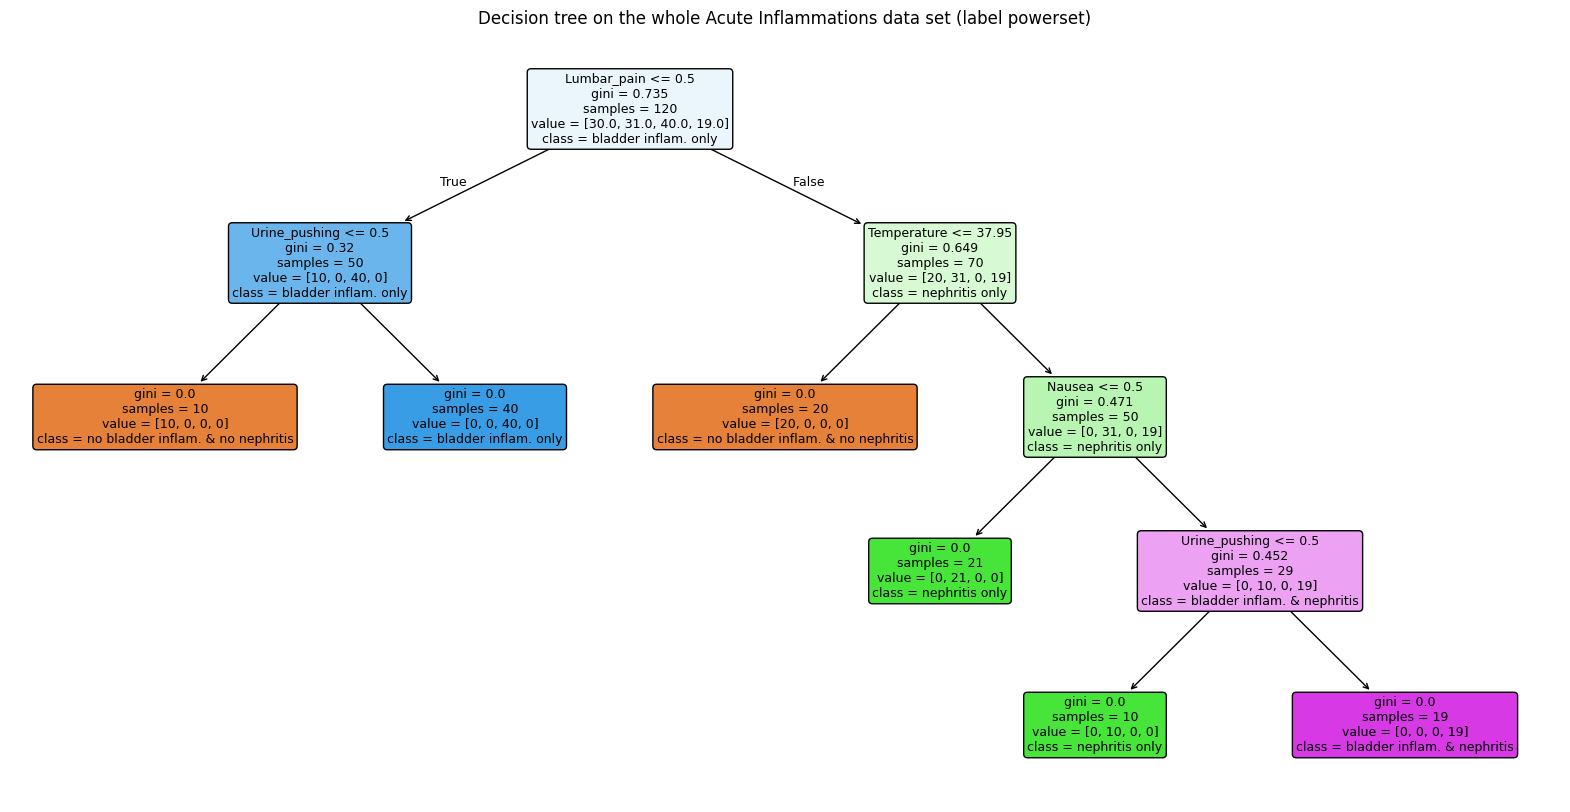

In [3]:
feature_names = acute_cols[:6]
X1 = acute[feature_names].values
d1 = acute["Inflammation_of_urinary_bladder"].values
d2 = acute["Nephritis_of_renal_pelvis"].values

y1 = d1 * 2 + d2
powerset_names = {0: "no bladder inflam. & no nephritis",
                  1: "nephritis only",
                  2: "bladder inflam. only",
                  3: "bladder inflam. & nephritis"}
present = sorted(np.unique(y1))
class_names = [powerset_names[c] for c in present]
print("Label-powerset class counts:")
print(pd.Series(y1).map(powerset_names).value_counts())

full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
full_tree.fit(X1, y1)
print("\nDepth:", full_tree.get_depth(), "| Leaves:", full_tree.get_n_leaves(),
      "| Training accuracy:", full_tree.score(X1, y1))

plt.figure(figsize=(20, 10))
plot_tree(full_tree, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, fontsize=9)
plt.title("Decision tree on the whole Acute Inflammations data set (label powerset)")
plt.show()

Q1.(c) Converting the decision rules into a set of IF-THEN rules

In [4]:
def tree_to_rules(clf, feat_names, cls_names):
    t = clf.tree_
    rules = []

    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = feat_names[t.feature[node]], t.threshold[node]
            recurse(t.children_left[node], conds + [f"({name} <= {thr:.2f})"])
            recurse(t.children_right[node], conds + [f"({name} > {thr:.2f})"])
        else:
            counts = t.value[node][0]
            label = cls_names[int(np.argmax(counts))]
            n = int(t.n_node_samples[node])
            cond = " AND ".join(conds) if conds else "(always)"
            rules.append(f"IF {cond} THEN class = '{label}'   [samples = {n}]")

    recurse(0, [])
    return rules


full_rules = tree_to_rules(full_tree, feature_names, class_names)
print(f"Full tree: {len(full_rules)} rules\n")
for i, r in enumerate(full_rules, 1):
    print(f"Rule {i}: {r}")

Full tree: 6 rules

Rule 1: IF (Lumbar_pain <= 0.50) AND (Urine_pushing <= 0.50) THEN class = 'no bladder inflam. & no nephritis'   [samples = 10]
Rule 2: IF (Lumbar_pain <= 0.50) AND (Urine_pushing > 0.50) THEN class = 'bladder inflam. only'   [samples = 40]
Rule 3: IF (Lumbar_pain > 0.50) AND (Temperature <= 37.95) THEN class = 'no bladder inflam. & no nephritis'   [samples = 20]
Rule 4: IF (Lumbar_pain > 0.50) AND (Temperature > 37.95) AND (Nausea <= 0.50) THEN class = 'nephritis only'   [samples = 21]
Rule 5: IF (Lumbar_pain > 0.50) AND (Temperature > 37.95) AND (Nausea > 0.50) AND (Urine_pushing <= 0.50) THEN class = 'nephritis only'   [samples = 10]
Rule 6: IF (Lumbar_pain > 0.50) AND (Temperature > 37.95) AND (Nausea > 0.50) AND (Urine_pushing > 0.50) THEN class = 'bladder inflam. & nephritis'   [samples = 19]


Q1.(d) Applying Cost-complexity pruning to find a minimal tree with highly interpretable rules

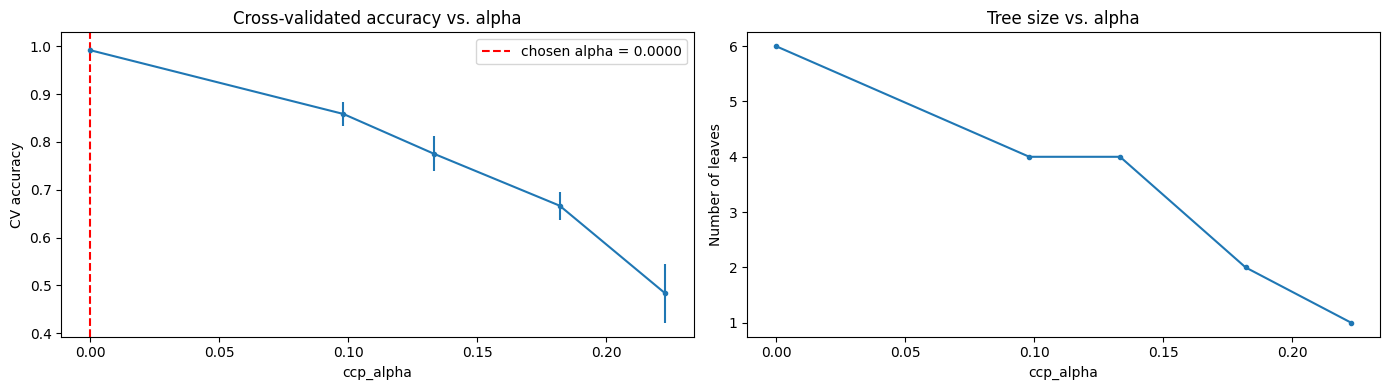

Chosen ccp_alpha = 0.00000
Pruned tree: depth = 4, leaves = 6, CV accuracy = 0.9917, training accuracy = 1.0000


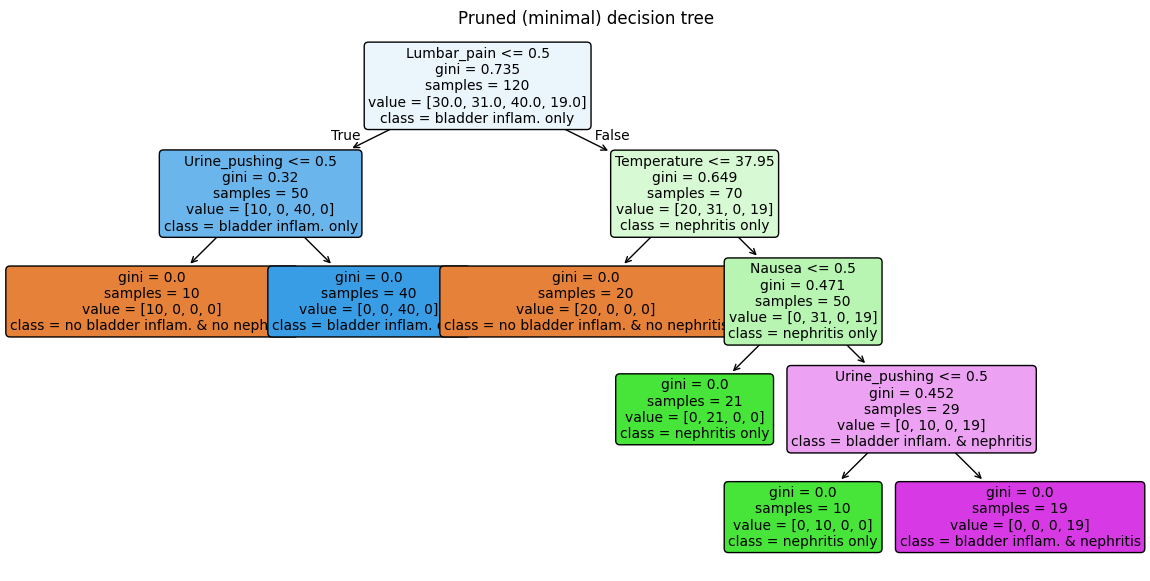


Pruned tree: 6 rules

Rule 1: IF (Lumbar_pain <= 0.50) AND (Urine_pushing <= 0.50) THEN class = 'no bladder inflam. & no nephritis'   [samples = 10]
Rule 2: IF (Lumbar_pain <= 0.50) AND (Urine_pushing > 0.50) THEN class = 'bladder inflam. only'   [samples = 40]
Rule 3: IF (Lumbar_pain > 0.50) AND (Temperature <= 37.95) THEN class = 'no bladder inflam. & no nephritis'   [samples = 20]
Rule 4: IF (Lumbar_pain > 0.50) AND (Temperature > 37.95) AND (Nausea <= 0.50) THEN class = 'nephritis only'   [samples = 21]
Rule 5: IF (Lumbar_pain > 0.50) AND (Temperature > 37.95) AND (Nausea > 0.50) AND (Urine_pushing <= 0.50) THEN class = 'nephritis only'   [samples = 10]
Rule 6: IF (Lumbar_pain > 0.50) AND (Temperature > 37.95) AND (Nausea > 0.50) AND (Urine_pushing > 0.50) THEN class = 'bladder inflam. & nephritis'   [samples = 19]


In [5]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X1, y1)
alphas = np.unique(np.round(path.ccp_alphas, 10))

n_splits = int(max(2, min(5, np.bincount(y1)[np.bincount(y1) > 0].min())))
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

cv_mean, cv_se, n_leaves = [], [], []
for a in alphas:
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    s = cross_val_score(clf, X1, y1, cv=skf)
    cv_mean.append(s.mean())
    cv_se.append(s.std(ddof=1) / np.sqrt(len(s)))
    n_leaves.append(clf.fit(X1, y1).get_n_leaves())
cv_mean, cv_se, n_leaves = map(np.array, (cv_mean, cv_se, n_leaves))

best = np.argmax(cv_mean)
threshold = cv_mean[best] - cv_se[best]
chosen = max(i for i in range(len(alphas)) if cv_mean[i] >= threshold)
best_alpha = alphas[chosen]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].errorbar(alphas, cv_mean, yerr=cv_se, marker="o", ms=3)
ax[0].axvline(best_alpha, color="r", ls="--", label=f"chosen alpha = {best_alpha:.4f}")
ax[0].set_xlabel("ccp_alpha"); ax[0].set_ylabel("CV accuracy"); ax[0].legend()
ax[0].set_title("Cross-validated accuracy vs. alpha")
ax[1].plot(alphas, n_leaves, marker="o", ms=3)
ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("Number of leaves")
ax[1].set_title("Tree size vs. alpha")
plt.tight_layout(); plt.show()

pruned = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha).fit(X1, y1)
print(f"Chosen ccp_alpha = {best_alpha:.5f}")
print(f"Pruned tree: depth = {pruned.get_depth()}, leaves = {pruned.get_n_leaves()}, "
      f"CV accuracy = {cv_mean[chosen]:.4f}, training accuracy = {pruned.score(X1, y1):.4f}")

plt.figure(figsize=(14, 7))
plot_tree(pruned, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, fontsize=10)
plt.title("Pruned (minimal) decision tree")
plt.show()

pruned_rules = tree_to_rules(pruned, feature_names, class_names)
print(f"\nPruned tree: {len(pruned_rules)} rules\n")
for i, r in enumerate(pruned_rules, 1):
    print(f"Rule {i}: {r}")

The tree is already minimal, and any further pruning hurts accuracy.

Q2.(a) Loading the Communities and Crime data

In [6]:
Q2_DATA_DIR = "/Users/sharvari/Downloads/communities+and+crime" 
Q2_DATA_FILE = "communities.data"
Q2_NAMES_FILE = "communities.names"       
raw_c = read_bytes(Q2_DATA_DIR, Q2_DATA_FILE)

try:
    names_txt = read_bytes(Q2_DATA_DIR, Q2_NAMES_FILE).decode("latin-1")
    attr_names = re.findall(r"^@attribute\s+(\S+)", names_txt, flags=re.M)
except FileNotFoundError:
    attr_names = []

comm = pd.read_csv(io.BytesIO(raw_c), header=None, na_values="?")
if len(attr_names) != comm.shape[1]:
    attr_names = [f"attr_{i}" for i in range(comm.shape[1] - 1)] + ["ViolentCrimesPerPop"]
comm.columns = attr_names
print("Full data shape:", comm.shape)

TRAIN_N = 1495
train_raw, test_raw = comm.iloc[:TRAIN_N].copy(), comm.iloc[TRAIN_N:].copy()
print("Train:", train_raw.shape, "| Test:", test_raw.shape)

Full data shape: (1994, 128)
Train: (1495, 128) | Test: (499, 128)


Q2.(b)Using data imputation for missing values and removing non-predictive features

In [7]:
TARGET = comm.columns[-1]               
non_predictive = list(comm.columns[:5])
print("Ignored non-predictive features:", non_predictive)

feat_cols = [c for c in comm.columns if c not in non_predictive + [TARGET]]
print("Number of predictive features:", len(feat_cols))
print("Missing values before imputation (train):", int(train_raw[feat_cols].isna().sum().sum()))

imp = SimpleImputer(strategy="mean", keep_empty_features=True)
Xtr = pd.DataFrame(imp.fit_transform(train_raw[feat_cols]), columns=feat_cols)
Xte = pd.DataFrame(imp.transform(test_raw[feat_cols]), columns=feat_cols)
ytr = train_raw[TARGET].values
yte = test_raw[TARGET].values
print("Missing values after imputation (train/test):",
      int(Xtr.isna().sum().sum()), int(Xte.isna().sum().sum()))

Ignored non-predictive features: ['state', 'county', 'community', 'communityname', 'fold']
Number of predictive features: 122
Missing values before imputation (train): 27633
Missing values after imputation (train/test): 0 0


Q2.(c)Correlation matrix of the features

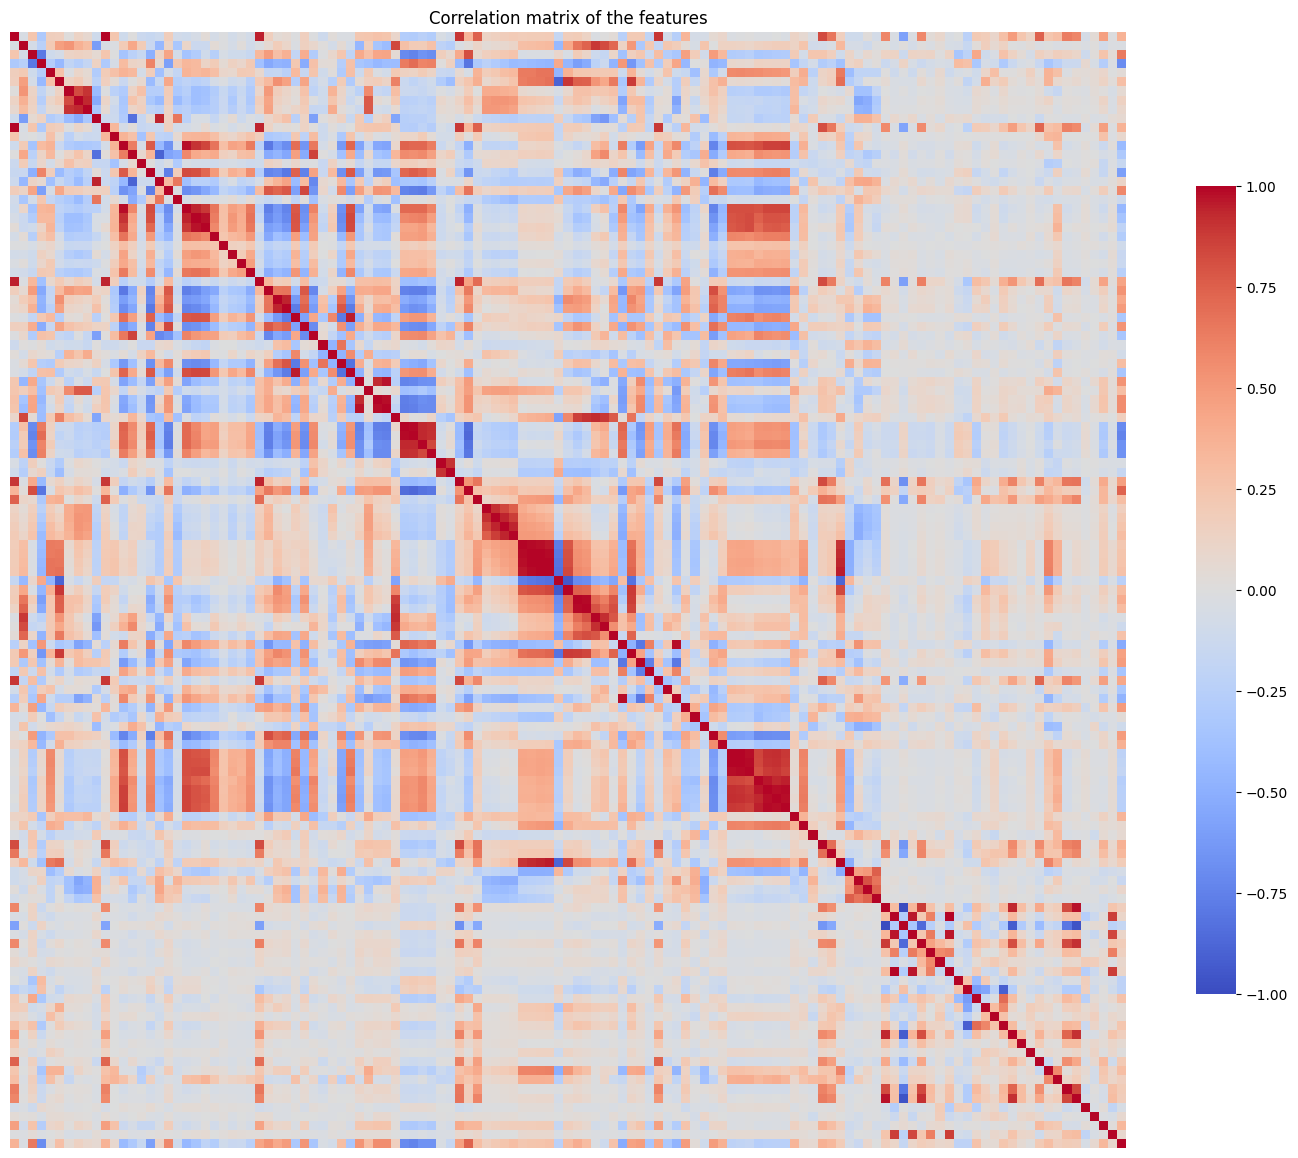

Features most correlated with the response:
PctIlleg            0.741866
PctKids2Par         0.741233
PctFam2Par          0.710619
racePctWhite        0.690614
PctTeen2Par         0.668713
PctYoungKids2Par    0.666485
racepctblack        0.644094
pctWInvInc          0.586759
pctWPubAsst         0.581713
FemalePctDiv        0.561824
Name: ViolentCrimesPerPop, dtype: float64


In [8]:
corr_df = pd.concat([Xtr, pd.Series(ytr, name=TARGET)], axis=1)
corr = corr_df.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, square=True,
            cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix of the features")
plt.show()

print("Features most correlated with the response:")
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(10))

Q2.(d)Calculating the coefficient of variation for each feature

In [9]:
cv_series = Xtr.std(ddof=1) / Xtr.mean()
cv_table = cv_series.sort_values(ascending=False).rename("CV")
print(cv_table.to_string())

NumStreet                4.292923
NumInShelters            3.470952
NumIlleg                 3.058964
NumImmig                 2.926635
LemasPctOfficDrugUn      2.552946
NumUnderPov              2.342443
population               2.241105
numbUrban                2.038461
HousVacant               1.968467
LandArea                 1.645408
racePctHisp              1.612091
PctNotSpeakEnglWell      1.456618
racepctblack             1.428885
PctUsePubTrans           1.397110
racePctAsian             1.359100
PctRecentImmig           1.288287
PctRecImmig5             1.286184
PctRecImmig10            1.270476
PctRecImmig8             1.265579
PctPersDenseHous         1.132926
PctForeignBorn           1.065880
PctVacantBoarded         1.054827
PctHousNoPhone           0.922765
PctIlleg                 0.921550
OwnOccMedVal             0.889410
OwnOccHiQuart            0.883583
PopDens                  0.864499
OwnOccLowQuart           0.859566
PctWOFullPlumb           0.843206
LemasSwornFT  

Q2.(e)Scatter plots and box plots for the ⌊√128⌋ features with the highest CV

floor(sqrt(128)) = 11; features with highest CV:
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
LandArea               1.645408
racePctHisp            1.612091
Name: CV, dtype: float64


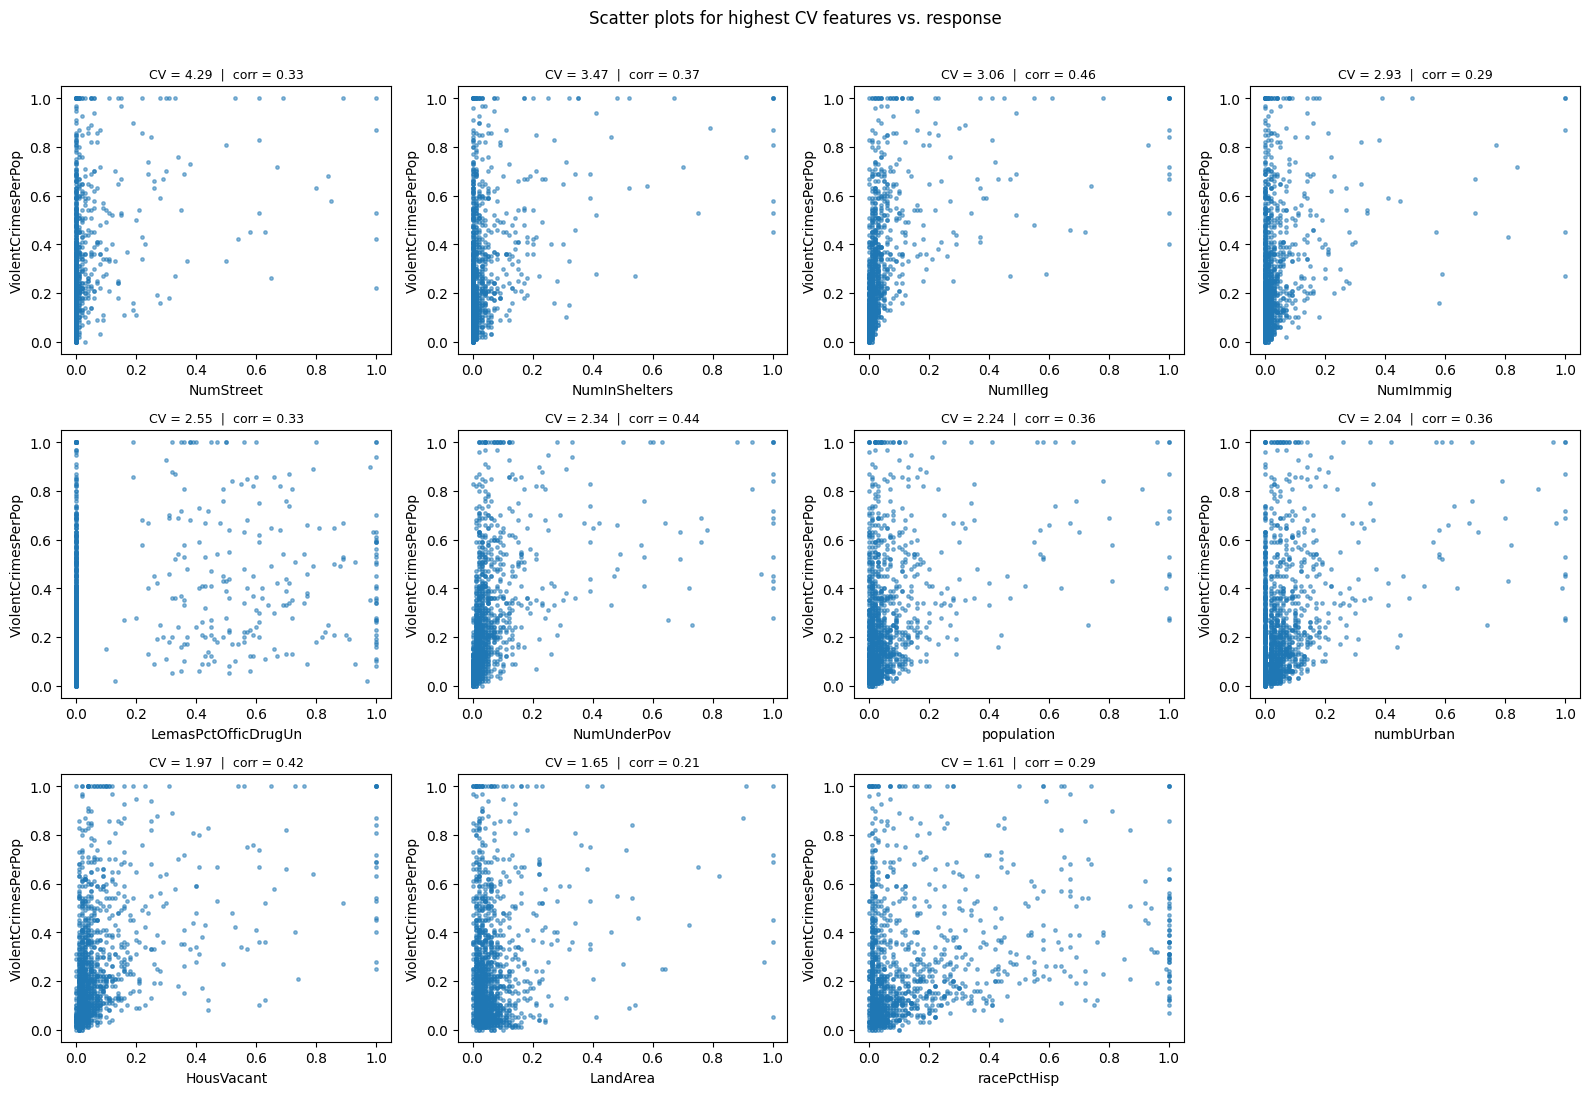

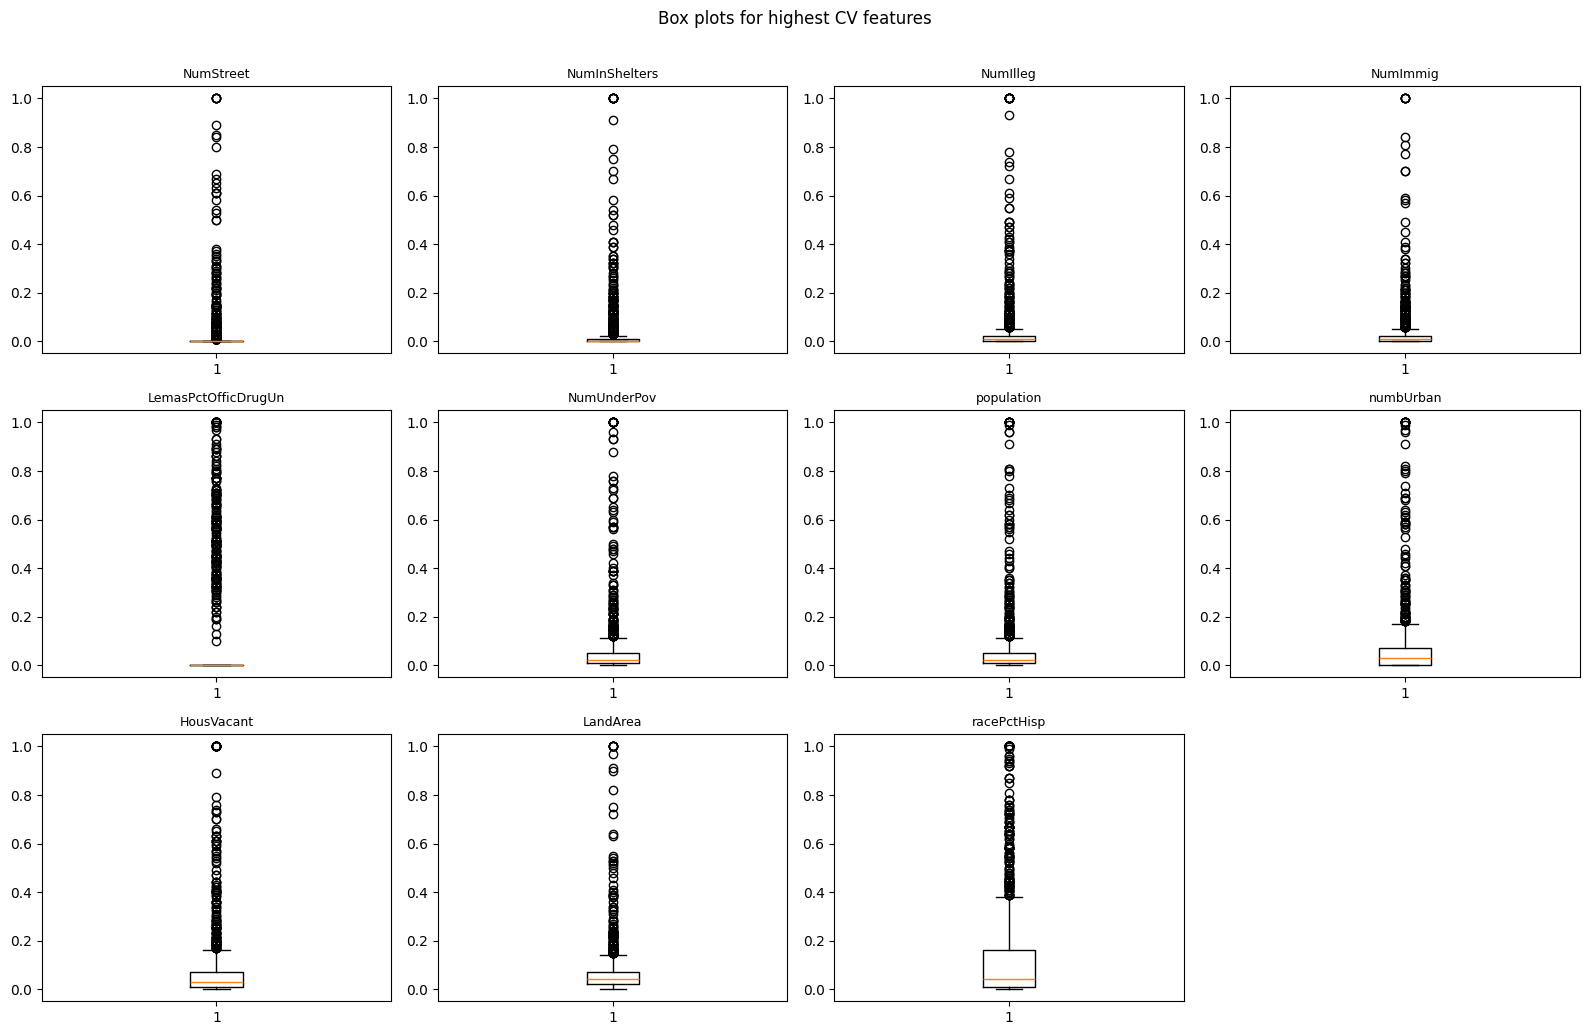

In [10]:
k = int(np.floor(np.sqrt(128)))          # = 11
top_feats = list(cv_table.index[:k])
print(f"floor(sqrt(128)) = {k}; features with highest CV:")
print(cv_table.head(k))

ncols = 4
nrows = int(np.ceil(k / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows))
for ax, f in zip(axes.ravel(), top_feats):
    ax.scatter(Xtr[f], ytr, s=6, alpha=0.5)
    ax.set_xlabel(f); ax.set_ylabel(TARGET)
    ax.set_title(f"CV = {cv_table[f]:.2f}  |  corr = {corr.loc[f, TARGET]:.2f}", fontsize=9)
for ax in axes.ravel()[k:]:
    ax.axis("off")
plt.suptitle("Scatter plots for highest CV features vs. response", y=1.01)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows))
for ax, f in zip(axes.ravel(), top_feats):
    ax.boxplot(Xtr[f], vert=True)
    ax.set_title(f, fontsize=9)
for ax in axes.ravel()[k:]:
    ax.axis("off")
plt.suptitle("Box plots for highest CV features", y=1.01)
plt.tight_layout(); plt.show()


Can we draw conclusions about the significance of those features just from the scatter plots?


No, I don’t think we can say this reliably from the scatter plots only.A high CV only means that a feature’s values are spread out a lot compared to its average. In this data, that mostly happens because the feature is close to zero for most communities and has a few very large values. The box plots show this too, since they have many outliers.The scatter plots only show how one feature relates to the crime rate on its own. They may incline at a trend where the correlation in each plot’s title helps here, but they have some limits.They can’t show a feature’s effect once the other features are taken into account. Many features are strongly correlated with each other as the correlation matrix shows.They don’t give any measure of statistical significance.A few extreme points can make a pattern look stronger than it is or hide a real one.

Q2.(f)Linear model fitted with least squares for training set and test error

In [11]:
def test_mse(model, Xa, ya):
    return mean_squared_error(ya, model.predict(Xa))

results = {}

ols = LinearRegression().fit(Xtr, ytr)
results["OLS"] = test_mse(ols, Xte, yte)
print(f"test MSE = {results['OLS']:.5f}   train MSE = {test_mse(ols, Xtr, ytr):.5f}")

test MSE = 0.01814   train MSE = 0.01631


Q2.(g)Ridge regression where λ chosen by cross validation

In [12]:
ridge = RidgeCV(alphas=np.logspace(-4, 3, 100), cv=KFold(10, shuffle=True, random_state=RANDOM_STATE))
ridge.fit(Xtr, ytr)
results["Ridge"] = test_mse(ridge, Xte, yte)
print(f"Ridge: best lambda (alpha) = {ridge.alpha_:.5f}")
print(f"Ridge test MSE = {results['Ridge']:.5f}")

Ridge: best lambda (alpha) = 3.35160
Ridge test MSE = 0.01755


Q2.(h)LASSO where λ chosen by cross-validation for raw features and standardized features

In [13]:
cv10 = KFold(10, shuffle=True, random_state=RANDOM_STATE)

lasso = LassoCV(cv=cv10, n_alphas=100, max_iter=100000, random_state=RANDOM_STATE)
lasso.fit(Xtr, ytr)
results["LASSO (given features)"] = test_mse(lasso, Xte, yte)
sel = [f for f, c in zip(feat_cols, lasso.coef_) if c != 0]
print(f"LASSO (given features): best lambda = {lasso.alpha_:.6f}")
print(f"  test MSE = {results['LASSO (given features)']:.5f}")
print(f"  {len(sel)} selected variables:")
print("  ", sel)

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
lasso_s = LassoCV(cv=cv10, n_alphas=100, max_iter=100000, random_state=RANDOM_STATE)
lasso_s.fit(Xtr_s, ytr)
results["LASSO (standardized)"] = test_mse(lasso_s, Xte_s, yte)
sel_s = [f for f, c in zip(feat_cols, lasso_s.coef_) if c != 0]
print(f"\nLASSO (standardized features): best lambda = {lasso_s.alpha_:.6f}")
print(f"  test MSE = {results['LASSO (standardized)']:.5f}")
print(f"  {len(sel_s)} selected variables:")
print("  ", sel_s)

print("\nComparison of the two LASSO fits")
print(pd.DataFrame({
    "lambda": [lasso.alpha_, lasso_s.alpha_],
    "selected variables": [len(sel), len(sel_s)],
    "test MSE": [results["LASSO (given features)"], results["LASSO (standardized)"]]},
    index=["given (normalized) features", "standardized features"]))
print("Variables selected by both:", len(set(sel) & set(sel_s)),
      "| no. of only given:", len(set(sel) - set(sel_s)),
      "| no. of only standardized:", len(set(sel_s) - set(sel)))

LASSO (given features): best lambda = 0.000125
  test MSE = 0.01774
  75 selected variables:
   ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInS

Q2.(i)principal components regression where  M is chosen by cross-validation

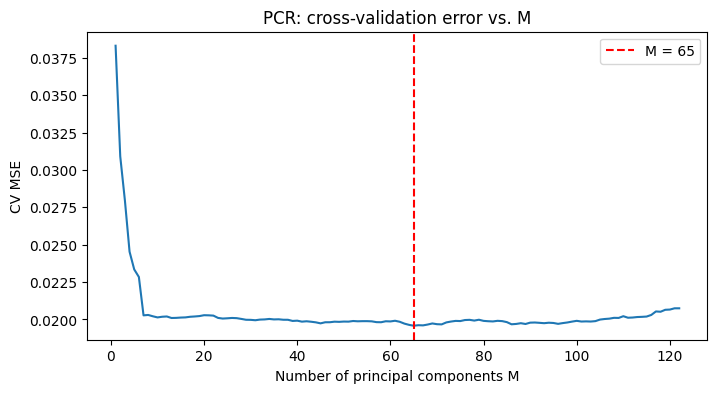

PCR: best M = 65
PCR test MSE = 0.01847


In [14]:
pcr = Pipeline([("pca", PCA(random_state=RANDOM_STATE)), ("ols", LinearRegression())])
grid = GridSearchCV(pcr, {"pca__n_components": list(range(1, Xtr.shape[1] + 1))},
                    cv=cv10, scoring="neg_mean_squared_error", n_jobs=-1)
grid.fit(Xtr, ytr)
best_M = grid.best_params_["pca__n_components"]
results["PCR"] = test_mse(grid.best_estimator_, Xte, yte)

cv_mse = -grid.cv_results_["mean_test_score"]
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cv_mse) + 1), cv_mse)
plt.axvline(best_M, color="r", ls="--", label=f"M = {best_M}")
plt.xlabel("Number of principal components M"); plt.ylabel("CV MSE"); plt.legend()
plt.title("PCR: cross-validation error vs. M"); plt.show()
print(f"PCR: best M = {best_M}")
print(f"PCR test MSE = {results['PCR']:.5f}")

Q2.(j)L1-penalized gradient boosting tree where α is chosen by cross-validation

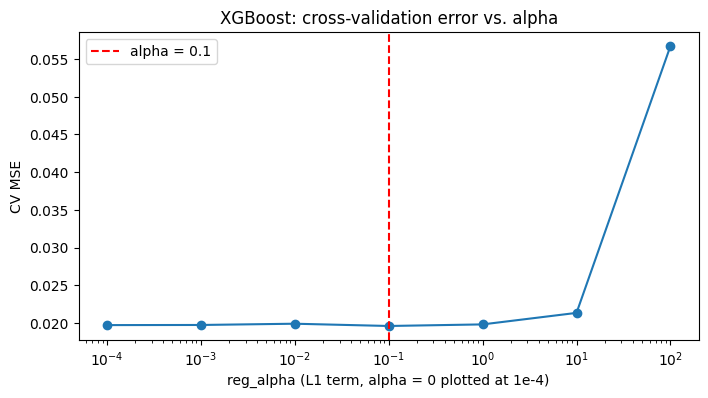

XGBoost: best alpha (reg_alpha) = 0.1
XGBoost test MSE = 0.01619


In [15]:
try:
    from xgboost import XGBRegressor
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    from xgboost import XGBRegressor
alpha_grid = [0, 0.001, 0.01, 0.1, 1, 10, 100]
xgb = XGBRegressor(booster="gbtree", n_estimators=300, learning_rate=0.05, max_depth=3,
                   subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                   random_state=RANDOM_STATE, n_jobs=-1)
gs = GridSearchCV(xgb, {"reg_alpha": alpha_grid}, cv=cv10,
                  scoring="neg_mean_squared_error", n_jobs=1)
gs.fit(Xtr, ytr)
best_alpha_xgb = gs.best_params_["reg_alpha"]
results["XGBoost (L1, gbtree)"] = test_mse(gs.best_estimator_, Xte, yte)
plt.figure(figsize=(8, 4))
plt.semilogx([max(a, 1e-4) for a in alpha_grid], -gs.cv_results_["mean_test_score"], marker="o")
plt.axvline(max(best_alpha_xgb, 1e-4), color="r", ls="--", label=f"alpha = {best_alpha_xgb}")
plt.xlabel("reg_alpha (L1 term, alpha = 0 plotted at 1e-4)"); plt.ylabel("CV MSE"); plt.legend()
plt.title("XGBoost: cross-validation error vs. alpha"); plt.show()
print(f"XGBoost: best alpha (reg_alpha) = {best_alpha_xgb}")
print(f"XGBoost test MSE = {results['XGBoost (L1, gbtree)']:.5f}")